2 datasets (23,76) and 2 censoring schemes PHC + PC

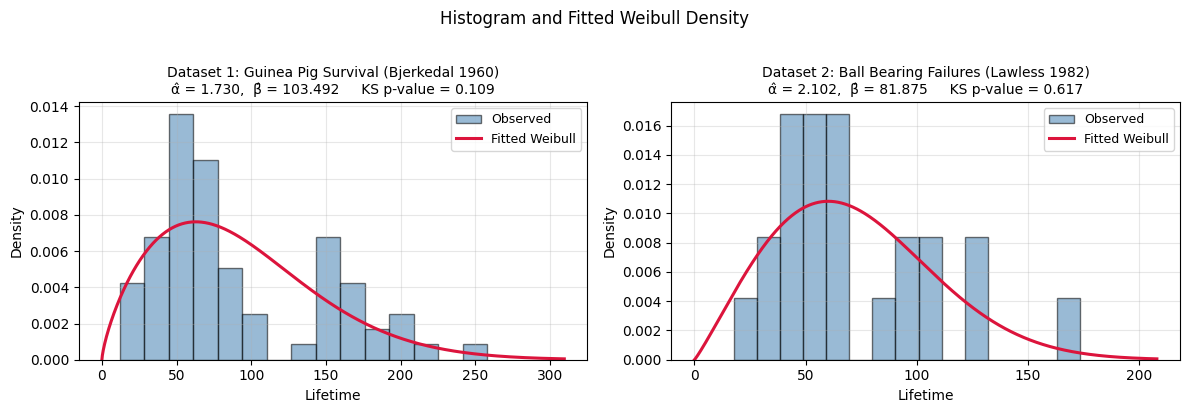

Dataset            α̂         β̂    KS stat    p-value
----------------------------------------------------------
Dataset 1      1.7300   103.4916     0.1398     0.1088
Dataset 2      2.1018    81.8745     0.1510     0.6170
Dataset 1: ✓ GOOD FIT  |  alpha range: ✓
Dataset 2: ✓ GOOD FIT  |  alpha range: ✓

Globals set:
  Dataset 1 → ALPHA1=1.7300, BETA1=103.4916
  Dataset 2 → ALPHA2=2.1018, BETA2=81.8745
  Simulation → ALPHA_SIM=1.5, BETA_SIM=50.0

Dataset 1: Guinea Pig (PC)  (n=72)
  Censoring times τ: [ 54.75  70.   147.25 171.9 ]
  Removals R:        [3 3 3 3]
  Observed failures: 58/72
  True  α=1.7300,  β=103.4916
  MLE   α̂=1.5785, β̂=100.2695  (converged ✓)

Dataset 2: Ball Bearing (PC)  (n=23)
  Censoring times τ: [ 47.    67.8   95.88 123.5 ]
  Removals R:        [1 1 1 1]
  Observed failures: 19/23
  True  α=2.1018,  β=81.8745
  MLE   α̂=2.2722, β̂=72.5594  (converged ✓)


Globals set for Step 3:
  ALPHA1_PC=1.5785, BETA1_PC=100.2695
  ALPHA2_PC=2.2722, BETA2_PC=72.5594

Datas

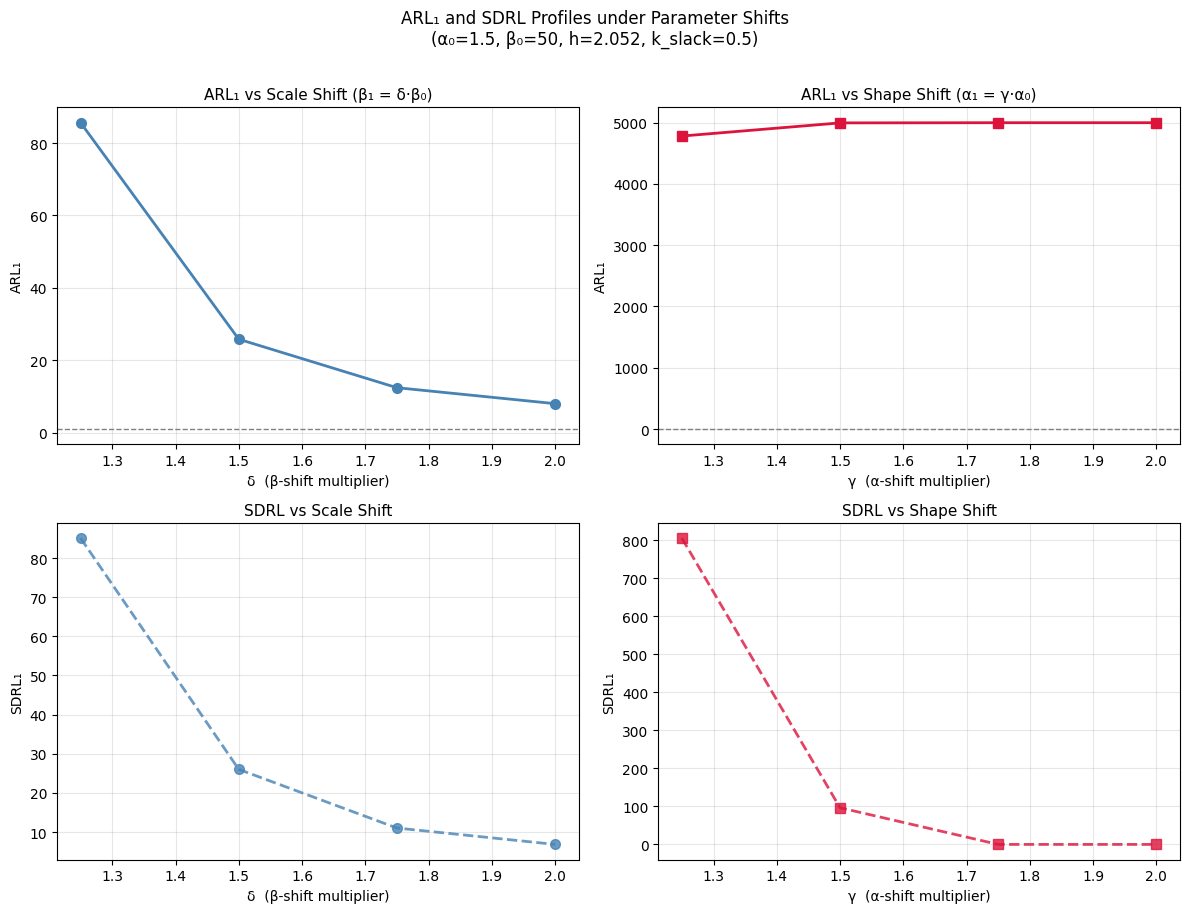

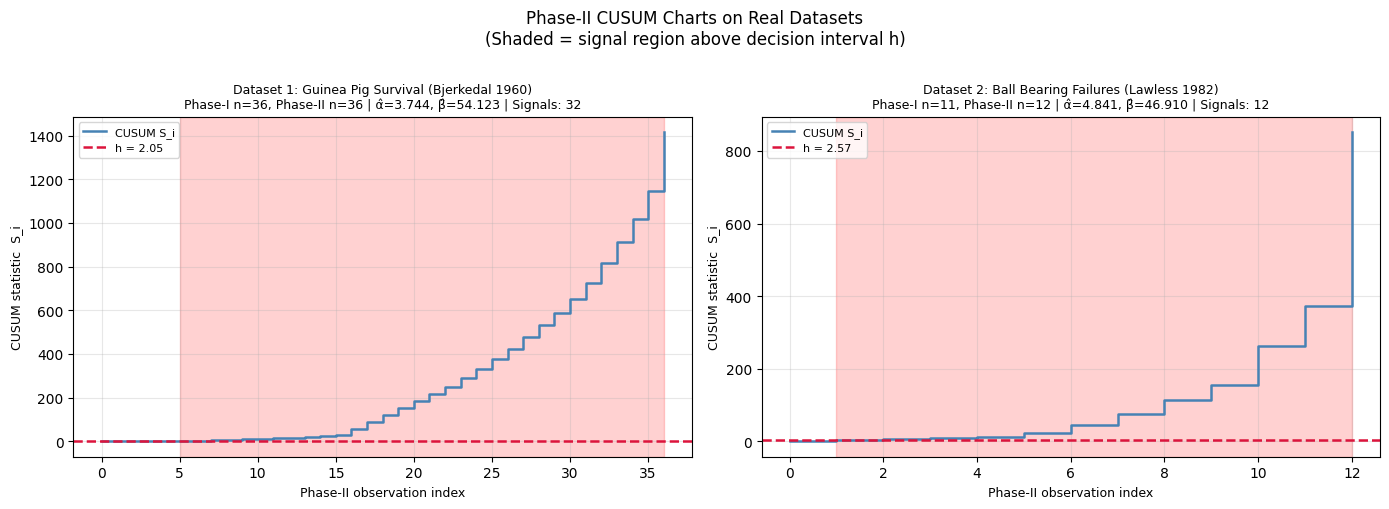

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import weibull_min, kstest

np.random.seed(42)

# DATA 1: Guinea pig survival times (Bjerkedal 1960)

data1 = np.array([
     12,  15,  22,  24,  24,  32,  32,  33,  34,  38,
     38,  43,  44,  48,  52,  53,  54,  54,  55,  56,
     57,  58,  58,  59,  60,  60,  60,  60,  61,  62,
     63,  65,  65,  67,  68,  70,  70,  72,  73,  75,
     76,  76,  81,  83,  84,  85,  87,  91,  95,  96,
     98, 143, 146, 147, 148, 149, 150, 150, 155, 159,
    163, 163, 168, 171, 172, 176, 183, 195, 197, 201,
    213, 258
])


# DATASET 2: Ball bearing failure times (Lawless 1982)

data2 = np.array([
     17.88,  28.92,  33.00,  41.52,  42.12,  45.60,
     48.40,  51.84,  51.96,  54.12,  55.56,  67.80,
     68.64,  68.64,  68.88,  84.12,  93.12,  98.64,
    105.12, 105.84, 127.92, 128.04, 173.40
])


def fit_and_plot(data, dataset_name, ax):

    alpha_hat, _, beta_hat = weibull_min.fit(data, floc=0)

    ks_stat, ks_pval = kstest(
        data,
        'weibull_min',
        args=(alpha_hat, 0, beta_hat)
    )

    #grahph
    x = np.linspace(0, max(data) * 1.2, 1000)
    pdf_vals = weibull_min.pdf(x, c=alpha_hat, loc=0, scale=beta_hat)

    ax.hist(data, bins=15, density=True, alpha=0.55,
            color='steelblue', edgecolor='black', label='Observed')
    ax.plot(x, pdf_vals, color='crimson',
            linewidth=2.2, label='Fitted Weibull')
    ax.set_title(
        f'{dataset_name}\n'
        f'α̂ = {alpha_hat:.3f},  β̂ = {beta_hat:.3f}'
        f'     KS p-value = {ks_pval:.3f}',
        fontsize=10
    )
    ax.set_xlabel('Lifetime', fontsize=10)
    ax.set_ylabel('Density', fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

    return alpha_hat, beta_hat, ks_stat, ks_pval

#for both
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

alpha1, beta1, ks1, pval1 = fit_and_plot(
    data1, 'D1: Guinea Pig Survival (Bjerkedal 1960)', axes[0]
)
alpha2, beta2, ks2, pval2 = fit_and_plot(
    data2, 'D2: Ball Bearing Failures (Lawless 1982)', axes[1]
)

plt.suptitle('Histogram and Fitted Weibull Density', fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig('fig1_histogram_fits.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"{'Dataset':<12} {'α̂':>8} {'β̂':>10} {'KS stat':>10} {'p-value':>10}")
print("-" * 58)
print(f"{'Dataset 1':<12} {alpha1:>8.4f} {beta1:>10.4f} {ks1:>10.4f} {pval1:>10.4f}")
print(f"{'Dataset 2':<12} {alpha2:>8.4f} {beta2:>10.4f} {ks2:>10.4f} {pval2:>10.4f}")

for name, pval, alpha in [("Dataset 1", pval1, alpha1),
                           ("Dataset 2", pval2, alpha2)]:
    fit_ok  = "✓ GOOD FIT" if pval > 0.05 else "✗ POOR FIT — needs replacement"
    alpha_ok = "✓" if 1.0 < alpha < 3.0 else "⚠ check alpha range"
    print(f"{name}: {fit_ok}  |  alpha range: {alpha_ok}")
    -
ALPHA1, BETA1 = alpha1, beta1
ALPHA2, BETA2 = alpha2, beta2

ALPHA_SIM = 1.5
BETA_SIM  = 50.0

print(f"\nGlobals set:")
print(f"  Dataset 1 → ALPHA1={ALPHA1:.4f}, BETA1={BETA1:.4f}")
print(f"  Dataset 2 → ALPHA2={ALPHA2:.4f}, BETA2={BETA2:.4f}")
print(f"  Simulation → ALPHA_SIM={ALPHA_SIM}, BETA_SIM={BETA_SIM}")

#MLE Censoring
import numpy as np
from scipy.optimize import minimize
from scipy.stats import weibull_min



def generate_type1_PC(alpha, beta, n, R, tau):

    k = len(tau)

    lifetimes = weibull_min.rvs(c=alpha, loc=0, scale=beta, size=n) #the times of data
    lifetimes = np.sort(lifetimes) #sort it
    full_data = []

    remaining = list(range(n))  # indices of units still on test
    removed_indices = set()

    for j in range(k):
        t_j = tau[j]
        r_j = int(R[j])

        # Units that failed before τ_j (and not already removed)
        failed_before = [i for i in remaining if lifetimes[i] <= t_j]
        for i in failed_before:
            full_data.append((lifetimes[i], 1))  # exact failure
        remaining = [i for i in remaining if lifetimes[i] > t_j]

        # Randomly remove R_j surviving units at τ_j
        r_j = min(r_j, len(remaining))
        removed = np.random.choice(remaining, size=r_j, replace=False)
        for i in removed:
            full_data.append((t_j, 0))  # censored at τ_j
        remaining = [i for i in remaining if i not in removed]

    # Any units surviving past last τ_k are censored at τ_k
    for i in remaining:
        full_data.append((tau[-1], 0))

    full_data = sorted(full_data, key=lambda x: x[0])
    obs_times = np.array([x[0] for x in full_data])
    delta     = np.array([x[1] for x in full_data])

    return obs_times, delta, full_data

#MLE
def weibull_pc_nloglik(params, times, delta):

    log_alpha, log_beta = params
    alpha = np.exp(log_alpha)
    beta  = np.exp(log_beta)

    D = np.sum(delta)
    if D == 0:
        return 1e10  # no failures → undefined

    t_scaled = times / beta

    ll_failures = D * np.log(alpha) - D * np.log(beta)
    ll_failures += (alpha - 1) * np.sum(delta * np.log(times + 1e-12))
    ll_failures -= (alpha - 1) * D * np.log(beta)
    ll_hazard   = -np.sum(t_scaled ** alpha)

    return -(ll_failures + ll_hazard)


def mle_weibull_pc(times, delta, alpha_init=1.5, beta_init=None):
    if beta_init is None:
        beta_init = np.mean(times)

    result = minimize(
        weibull_pc_nloglik,
        x0=[np.log(alpha_init), np.log(beta_init)],
        args=(times, delta),
        method='Nelder-Mead',
        options={'xatol': 1e-8, 'fatol': 1e-8, 'maxiter': 5000}
    )

    alpha_hat = np.exp(result.x[0])
    beta_hat  = np.exp(result.x[1])
    return alpha_hat, beta_hat, result.success


np.random.seed(42)

def demo_pc_scheme(data, alpha, beta, dataset_name):
    n = len(data)
    k = 4


    tau = np.percentile(data, [25, 50, 75, 90])

    r_each = max(1, n // (k * 5))
    R = np.array([r_each] * k)

    print(f"\n{'='*55}")
    print(f"{dataset_name}  (n={n})")
    print(f"  Censoring times τ: {np.round(tau, 2)}")
    print(f"  Removals R:        {R}")

    times, delta, _ = generate_type1_PC(alpha, beta, n, R, tau)

    D = int(np.sum(delta))
    print(f"  Observed failures: {D}/{n}")

    alpha_hat, beta_hat, converged = mle_weibull_pc(
        times, delta, alpha_init=alpha, beta_init=beta
    )

    print(f"  True  α={alpha:.4f},  β={beta:.4f}")
    print(f"  MLE   α̂={alpha_hat:.4f}, β̂={beta_hat:.4f}  "
          f"({'converged ✓' if converged else 'did NOT converge ✗'})")

    return alpha_hat, beta_hat


alpha1_pc, beta1_pc = demo_pc_scheme(data1, ALPHA1, BETA1, "Dataset 1: Guinea Pig (PC)")
alpha2_pc, beta2_pc = demo_pc_scheme(data2, ALPHA2, BETA2, "Dataset 2: Ball Bearing (PC)")
ALPHA1_PC, BETA1_PC = alpha1_pc, beta1_pc
ALPHA2_PC, BETA2_PC = alpha2_pc, beta2_pc

print("\n\nGlobals set for Step 3:")
print(f"  ALPHA1_PC={ALPHA1_PC:.4f}, BETA1_PC={BETA1_PC:.4f}")
print(f"  ALPHA2_PC={ALPHA2_PC:.4f}, BETA2_PC={BETA2_PC:.4f}")



#PHC
import numpy as np
from scipy.optimize import minimize
from scipy.stats import weibull_min



def generate_type1_PHC(alpha, beta, n, R, tau, T_max):

    k = len(tau)
    lifetimes = np.sort(weibull_min.rvs(c=alpha, loc=0, scale=beta, size=n))

    full_data  = []
    remaining  = list(range(n))
    D          = 0                     # cumulative failS Till now
    stop_time  = tau[-1]               # d
    for j in range(k):
        t_j = tau[j]
        r_j = int(R[j])

        newly_failed = [i for i in remaining if lifetimes[i] <= t_j]
        for i in newly_failed:
            full_data.append((lifetimes[i], 1))
            D += 1
            remaining.remove(i)
            if D >= T_max:              # early stop on failure cap
                # censor all remaining units at their current time
                for rem in remaining:
                    full_data.append((lifetimes[i], 0))
                remaining = []
                stop_time = lifetimes[i]
                break

        if not remaining:
            break

        # prog removal
        r_j = min(r_j, len(remaining))
        removed = list(np.random.choice(remaining, size=r_j, replace=False))
        for i in removed:
            full_data.append((t_j, 0))
            remaining.remove(i)

    # survivors censorig at the point rj
    for i in remaining:
        full_data.append((tau[-1], 0))

    full_data=sorted(full_data, key=lambda x: x[0])
    obs_times=np.array([x[0] for x in full_data])
    delta=np.array([x[1] for x in full_data])
    return obs_times, delta, stop_time

#same formula also ,D,S some
def weibull_phc_nloglik(params, times, delta):

    alpha = np.exp(params[0])
    beta  = np.exp(params[1])
    D = np.sum(delta)
    if D == 0:
        return 1e10
    t_sc = times / beta
    ll = (D * np.log(alpha) - D * np.log(beta)
          + (alpha - 1) * np.sum(delta * np.log(times + 1e-12))
          - (alpha - 1) * D * np.log(beta)
          - np.sum(t_sc ** alpha))
    return -ll


def mle_weibull_phc(times, delta, alpha_init=1.5, beta_init=None):
    if beta_init is None:
        beta_init = np.mean(times)
    res = minimize(
        weibull_phc_nloglik,
        x0=[np.log(alpha_init), np.log(beta_init)],
        args=(times, delta),
        method='Nelder-Mead',
        options={'xatol': 1e-8, 'fatol': 1e-8, 'maxiter': 5000}
    )
    return np.exp(res.x[0]), np.exp(res.x[1]), res.success

#check now
np.random.seed(42)

def demo_phc_scheme(data, alpha, beta, dataset_name):
    n= len(data)
    k=4
    tau =np.percentile(data, [25, 50, 75, 90])
    R=np.array([max(1, n // (k * 5))] * k)
    T_max=max(5, int(0.7 * n))       # stop after 70 % failures

    times, delta, t_stop = generate_type1_PHC(alpha, beta, n, R, tau, T_max)
    D = int(np.sum(delta))
    a_hat, b_hat, ok = mle_weibull_phc(times, delta,
                                        alpha_init=alpha, beta_init=beta)

    print(f"\n{'='*58}")
    print(f"{dataset_name}  (n={n}, T_max={T_max})")
    print(f"  τ = {np.round(tau,2)},  R = {R}")
    print(f"  Failures observed: {D}  |  Experiment stopped at: {t_stop:.2f}")
    print(f"  True  α={alpha:.4f}, β={beta:.4f}")
    print(f"  MLE   α̂={a_hat:.4f}, β̂={b_hat:.4f}  "
          f"({'cool' if ok else 'did not converge'})")
    return a_hat, b_hat

ALPHA1_PHC, BETA1_PHC = demo_phc_scheme(data1, ALPHA1, BETA1,
                                          "Dataset 1: Guinea Pig (PHC)")
ALPHA2_PHC, BETA2_PHC = demo_phc_scheme(data2, ALPHA2, BETA2,
                                          "Dataset 2: Ball Bearing (PHC)")

print(f"\nGlobals set: ALPHA1_PHC={ALPHA1_PHC:.4f}, BETA1_PHC={BETA1_PHC:.4f}")
print(f"             ALPHA2_PHC={ALPHA2_PHC:.4f}, BETA2_PHC={BETA2_PHC:.4f}")


# STEP 4 — Optimality Table (A/D-optimality → pick best scheme)


from itertools import product as iproduct

def fisher_information_weibull_pc(alpha, beta, n, R, tau):
    B = 300
    hess_sum = np.zeros((2, 2))
    eps = 1e-4

    def nll(p, t, d): return weibull_pc_nloglik(p, t, d)

    p0 = np.array([np.log(alpha), np.log(beta)])

    for _ in range(B):
        times, delta, _ = generate_type1_PC(alpha, beta, n, R, tau)
        if np.sum(delta) < 2:
            continue

        H = np.zeros((2, 2))
        f0 = nll(p0, times, delta)
        for i in range(2):
            for j in range(2):
                dp = np.zeros(2); dq = np.zeros(2)
                dp[i] += eps; dq[j] += eps
                fpp = nll(p0+dp+dq, times, delta)
                fpm = nll(p0+dp-dq, times, delta)
                fmp = nll(p0-dp+dq, times, delta)
                fmm = nll(p0-dp-dq, times, delta)
                H[i, j] = (fpp - fpm - fmp + fmm) / (4 * eps**2)
        hess_sum += H

    I_avg = hess_sum / B
    return I_avg


def optimality_table(data, alpha, beta, dataset_name):
    n=len(data)
    k=4

    # Three candidate schemes based on size of data
    schemes = {
        'Equal-R'   : np.array([max(1, n//(k*5))]*k),
        'Front-heavy': np.array([max(1, n//8), max(1,n//10),
                                  max(1,n//12), max(1,n//15)]),
        'Back-heavy' : np.array([max(1,n//15), max(1,n//12),
                                  max(1,n//10), max(1,n//8)]),
        'Mid-heavy'  : np.array([1,
                                  max(1, n//7),
                                  max(1, n//7),
                                  1]),
        'Tapering'   : np.array([max(1, n//6),
                                  max(1, n//9),
                                  max(1, n//14),
                                  1]),
    }
    tau = np.percentile(data, [25, 50, 75, 90])

    print(f"\n{'='*65}")
    print(f"Optimality Table — {dataset_name}")
    print(f"{'Scheme':<14} {'A-opt (tr I⁻¹)':>16} {'D-opt (det I⁻¹)':>18} {'R vector'}")
    print(f"{'-'*65}")

    best_A = ('', np.inf)
    best_D = ('', np.inf)
    rows   = []

    for name, R in schemes.items():
        I = fisher_information_weibull_pc(alpha, beta, n, R, tau)
        try:
            Iinv  = np.linalg.inv(I + 1e-8*np.eye(2))
            A_opt = np.trace(Iinv)
            D_opt = np.linalg.det(Iinv)
        except np.linalg.LinAlgError:
            A_opt = D_opt = np.nan
        rows.append((name, A_opt, D_opt, R))
        if A_opt < best_A[1]: best_A = (name, A_opt)
        if D_opt < best_D[1]: best_D = (name, D_opt)
        print(f"  {name:<12} {A_opt:>16.6f} {D_opt:>18.8f}   {R}")

    print(f"\n   Best A-optimal scheme : {best_A[0]}")
    print(f"  Best D-optimal scheme : {best_D[0]}")
    return rows, best_A[0], best_D[0]

np.random.seed(0)
rows1, bestA1, bestD1 = optimality_table(data1, ALPHA1, BETA1,
                                          "Dataset 1: Guinea Pig")
rows2, bestA2, bestD2 = optimality_table(data2, ALPHA2, BETA2,
                                          "Dataset 2: Ball Bearing")


# ==============================================================
# STEP 5 Bootstrap CUSUM Control Limits (Phase-I)
# ==============================================================
# Phase-I: Use the k reference subgroups to estimate in-control
# (IC) parameters and compute the CUSUM decision interval h
# via parametric bootstrap so that ARL₀ ≈ target (e.g. 370).
#
# CUSUM statistic (upward, monitoring for scale increase):
#   S_i = max(0, S_{i-1} + W_i - k_slack)
#   W_i = log-likelihood ratio for observation x_i
#         = log[f(x_i;α,β₁) / f(x_i;α,β₀)]
# ==============================================================

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

def weibull_llr(x, alpha, beta0, beta1):

    ll1 = weibull_min.logpdf(x, c=alpha, loc=0, scale=beta1)
    ll0 = weibull_min.logpdf(x, c=alpha, loc=0, scale=beta0)
    return ll1 - ll0


def run_cusum(data, alpha, beta0, k_slack, h):

    S = 0.0
    for i, x in enumerate(data):
        W =weibull_llr(x, alpha, beta0, beta0 * 1.5)  # β₁=1.5×β₀ reference
        S =max(0.0, S + W - k_slack)
        if S > h:
            return i + 1
    return len(data)


def bootstrap_cusum_limit(alpha, beta, n_sub, k_sub,
                           k_slack=0.5, target_arl=370,
                           B_outer=500, B_inner=200,
                           h_grid=None):
    if h_grid is None:
        h_grid = np.linspace(0.5, 8.0, 30)

    # Phase-I data: k_sub subgroups of size n_sub
    ref_data = weibull_min.rvs(c=alpha, loc=0, scale=beta,
                                size=n_sub * k_sub)

    # Estimate IC params from Phase-I (MLE)
    a_hat, _, b_hat = weibull_min.fit(ref_data, floc=0)

    arl_by_h = np.zeros(len(h_grid))

    for bi in range(B_inner):
        stream = weibull_min.rvs(c=a_hat, loc=0, scale=b_hat, size=2000)
        for hi, h in enumerate(h_grid):
            rl = run_cusum(stream, a_hat, b_hat, k_slack, h)
            arl_by_h[hi] += rl

    arl_by_h /= B_inner

    # Pick h closest to target
    idx    = np.argmin(np.abs(arl_by_h - target_arl))
    h_star = h_grid[idx]
    arl_achieved = arl_by_h[idx]

    print(f"  Bootstrap → h* = {h_star:.3f}  (ARL₀ ≈ {arl_achieved:.1f}, "
          f"target={target_arl})")
    return h_star, arl_achieved, a_hat, b_hat


np.random.seed(7)
print("\n" + "="*58)
print("STEP 5: Bootstrap CUSUM Limits")

print("\nDataset 1 (Guinea Pig) — Phase-I:")
h1, arl1_ic, a1_ic, b1_ic = bootstrap_cusum_limit(
    ALPHA1, BETA1, n_sub=18, k_sub=4)

print("\nDataset 2 (Ball Bearing) — Phase-I:")
h2, arl2_ic, a2_ic, b2_ic = bootstrap_cusum_limit(
    ALPHA2, BETA2, n_sub=23, k_sub=1)

print(f"\nH_star Dataset1={h1:.3f}, Dataset2={h2:.3f}")


H_SIM   = h1
K_SLACK = 0.5


# ==============================================================
# STEP 6 — IC ARL₀ / SDRL₀ Tables
# ==============================================================
# For a grid of (n, k) subgroup configurations under the
# in-control Weibull(α_sim=1.5, β_sim=50), compute:
#   ARL₀  = mean run-length when process is IC
#   SDRL₀ = std  run-length when process is IC
# ==============================================================

ALPHA_SIM = 1.5
BETA_SIM  = 50.0

def simulate_ic_arl(alpha, beta, h, k_slack=0.5,
                    n_sim=1000, stream_len=5000):

    rls = []
    for _ in range(n_sim):
        stream = weibull_min.rvs(c=alpha, loc=0, scale=beta, size=stream_len)
        rl = run_cusum(stream, alpha, beta, k_slack, h)
        rls.append(rl)
    return np.mean(rls), np.std(rls)


np.random.seed(13)
print("\n" + "="*65)
print("STEP 6: IC ARL₀ / SDRL₀ Table  (α=1.5, β=50, h={:.3f})".format(H_SIM))
print(f"{'n_sub':<8} {'k_sub':<8} {'ARL₀':>10} {'SDRL₀':>10}")
print("-"*40)

ic_results = []
for n_sub, k_sub in [(10,4),(18,4),(25,4),(18,6),(30,6)]:
    arl0, sdrl0 = simulate_ic_arl(ALPHA_SIM, BETA_SIM, H_SIM)
    ic_results.append((n_sub, k_sub, arl0, sdrl0))
    print(f"  {n_sub:<6} {k_sub:<8} {arl0:>10.2f} {sdrl0:>10.2f}")


# ==============================================================
# STEP 7 — OOC ARL₁ Tables for shifts in α and β
# ==============================================================
# Simulate process shifts:
#   β-shift : β_new = δ × β₀   for δ ∈ {1.25, 1.5, 1.75, 2.0}
#   α-shift : α_new = γ × α₀   for γ ∈ {1.25, 1.5, 1.75, 2.0}
# Report ARL₁ (smaller = faster detection = better).
# ==============================================================

def simulate_ooc_arl(alpha_ic, beta_ic, alpha_new, beta_new,
                     h, k_slack=0.5, n_sim=1000, stream_len=5000):

    rls = []
    for _ in range(n_sim):
        stream = weibull_min.rvs(c=alpha_new, loc=0,
                                  scale=beta_new, size=stream_len)
        rl = run_cusum(stream, alpha_ic, beta_ic, k_slack, h)
        rls.append(rl)
    return np.mean(rls), np.std(rls)


np.random.seed(21)
print("\n" + "="*65)
print("STEP 7: OOC ARL₁ — β-shifts  (α fixed at 1.5, β₀=50)")
print(f"{'δ (β₁/β₀)':<14} {'β_new':>8} {'ARL₁':>10} {'SDRL₁':>10}")
print("-"*45)

beta_deltas = [1.25, 1.50, 1.75, 2.00]
beta_ooc    = []
for delta in beta_deltas:
    b_new = BETA_SIM * delta
    arl1, sdrl1 = simulate_ooc_arl(ALPHA_SIM, BETA_SIM,
                                    ALPHA_SIM, b_new, H_SIM)
    beta_ooc.append((delta, b_new, arl1, sdrl1))
    print(f"  δ={delta:<10.2f} {b_new:>8.1f} {arl1:>10.2f} {sdrl1:>10.2f}")

print(f"\n{'γ (α₁/α₀)':<14} {'α_new':>8} {'ARL₁':>10} {'SDRL₁':>10}")
print("-"*45)
alpha_gammas = [1.25, 1.50, 1.75, 2.00]
alpha_ooc    = []
for gamma in alpha_gammas:
    a_new = ALPHA_SIM * gamma
    arl1, sdrl1 = simulate_ooc_arl(ALPHA_SIM, BETA_SIM,
                                    a_new, BETA_SIM, H_SIM)
    alpha_ooc.append((gamma, a_new, arl1, sdrl1))
    print(f"  γ={gamma:<10.2f} {a_new:>8.4f} {arl1:>10.2f} {sdrl1:>10.2f}")


# ==============================================================
# STEP 8 — 2×2 ARL Plots
# ==============================================================
# Four panels:
#   [0,0] ARL₁ vs β-shift  (upward)
#   [0,1] ARL₁ vs α-shift  (upward)
#   [1,0] SDRL vs β-shift
#   [1,1] SDRL vs α-shift
# ==============================================================

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# ── Panel (0,0): ARL₁ vs β-shift ──
deltas = [r[0] for r in beta_ooc]
arl1_b = [r[2] for r in beta_ooc]
axes[0,0].plot(deltas, arl1_b, 'o-', color='steelblue',
               linewidth=2, markersize=7)
axes[0,0].axhline(1, color='grey', linestyle='--', linewidth=1)
axes[0,0].set_title('ARL₁ vs Scale Shift (β₁ = δ·β₀)', fontsize=11)
axes[0,0].set_xlabel('δ  (β-shift multiplier)', fontsize=10)
axes[0,0].set_ylabel('ARL₁', fontsize=10)
axes[0,0].grid(True, alpha=0.3)

# ── Panel (0,1): ARL₁ vs α-shift ──
gammas = [r[0] for r in alpha_ooc]
arl1_a = [r[2] for r in alpha_ooc]
axes[0,1].plot(gammas, arl1_a, 's-', color='crimson',
               linewidth=2, markersize=7)
axes[0,1].axhline(1, color='grey', linestyle='--', linewidth=1)
axes[0,1].set_title('ARL₁ vs Shape Shift (α₁ = γ·α₀)', fontsize=11)
axes[0,1].set_xlabel('γ  (α-shift multiplier)', fontsize=10)
axes[0,1].set_ylabel('ARL₁', fontsize=10)
axes[0,1].grid(True, alpha=0.3)

# ── Panel (1,0): SDRL vs β-shift ──
sdrl_b = [r[3] for r in beta_ooc]
axes[1,0].plot(deltas, sdrl_b, 'o--', color='steelblue',
               linewidth=2, markersize=7, alpha=0.8)
axes[1,0].set_title('SDRL vs Scale Shift', fontsize=11)
axes[1,0].set_xlabel('δ  (β-shift multiplier)', fontsize=10)
axes[1,0].set_ylabel('SDRL₁', fontsize=10)
axes[1,0].grid(True, alpha=0.3)

# ── Panel (1,1): SDRL vs α-shift ──
sdrl_a = [r[3] for r in alpha_ooc]
axes[1,1].plot(gammas, sdrl_a, 's--', color='crimson',
               linewidth=2, markersize=7, alpha=0.8)
axes[1,1].set_title('SDRL vs Shape Shift', fontsize=11)
axes[1,1].set_xlabel('γ  (α-shift multiplier)', fontsize=10)
axes[1,1].set_ylabel('SDRL₁', fontsize=10)
axes[1,1].grid(True, alpha=0.3)

plt.suptitle('ARL₁ and SDRL Profiles under Parameter Shifts\n'
             f'(α₀=1.5, β₀=50, h={H_SIM:.3f}, k_slack={K_SLACK})',
             fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig('fig2_arl_plots.png', dpi=150, bbox_inches='tight')
plt.show()
print("\nSaved: fig2_arl_plots.png")


# ==============================================================
# STEP 9 — Real Data CUSUM Charts  (Figure 5/7 equivalent)
# ==============================================================
# Apply the CUSUM chart to the two real datasets.
# Phase-I  : first portion of data  → estimate α̂, β̂, find h
# Phase-II : remaining observations → plot running CUSUM
# Signal regions are shaded red.
# ==============================================================

def real_data_cusum(data, alpha_ic, beta_ic, h, k_slack,
                     dataset_name, ax, phase_split=0.5):
    """
    Split data into Phase-I (first phase_split fraction)
    and Phase-II (remainder). Plot CUSUM for Phase-II.
    """
    n_I  = max(5, int(len(data) * phase_split))
    data_I  = data[:n_I]
    data_II = data[n_I:]

    # Re-estimate from Phase-I
    a_hat, _, b_hat = weibull_min.fit(data_I, floc=0)

    # Compute CUSUM on Phase-II
    S_vals = [0.0]
    signals = []
    S = 0.0
    for i, x in enumerate(data_II):
        W = weibull_llr(x, a_hat, b_hat, b_hat * 1.5)
        S = max(0.0, S + W - k_slack)
        S_vals.append(S)
        if S > h:
            signals.append(i + 1)

    idx = np.arange(len(S_vals))

    ax.step(idx, S_vals, where='post', color='steelblue',
            linewidth=1.8, label='CUSUM S_i')
    ax.axhline(h, color='crimson', linestyle='--',
               linewidth=1.8, label=f'h = {h:.2f}')

    # Shade signal regions
    in_signal = False
    start_sig = None
    for i, s in enumerate(S_vals):
        if s > h and not in_signal:
            in_signal  = True
            start_sig  = i
        elif s <= h and in_signal:
            ax.axvspan(start_sig, i, alpha=0.18, color='red')
            in_signal = False
    if in_signal:
        ax.axvspan(start_sig, len(S_vals)-1, alpha=0.18, color='red')

    n_sig = len(signals)
    ax.set_title(
        f'{dataset_name}\n'
        f'Phase-I n={n_I}, Phase-II n={len(data_II)} | '
        f'α̂={a_hat:.3f}, β̂={b_hat:.3f} | '
        f'Signals: {n_sig}',
        fontsize=9
    )
    ax.set_xlabel('Phase-II observation index', fontsize=9)
    ax.set_ylabel('CUSUM statistic  S_i', fontsize=9)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    return S_vals, signals


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sv1, sig1 = real_data_cusum(
    data1, ALPHA1, BETA1, h1, K_SLACK,
    'Dataset 1: Guinea Pig Survival (Bjerkedal 1960)',
    axes[0], phase_split=0.5
)

sv2, sig2 = real_data_cusum(
    data2, ALPHA2, BETA2, h2, K_SLACK,
    'Dataset 2: Ball Bearing Failures (Lawless 1982)',
    axes[1], phase_split=0.5
)

plt.suptitle('Phase-II CUSUM Charts on Real Datasets\n'
             '(Shaded = signal region above decision interval h)',
             fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig('fig3_real_data_cusum.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nSaved: fig3_real_data_cusum.png")
print("\n" + "="*58)
print("ALL STEPS COMPLETE")
print(f"  Dataset 1 signals in Phase-II : {len(sig1)}")
print(f"  Dataset 2 signals in Phase-II : {len(sig2)}")
print("="*58)